# Homework – Week 4: Digital Twin Synchronization
**Course:** Simulations – Digital Twin  
**Team:** A – Indoor $\text{PM}_{2.5}$ (Weslaco Residence & TCEQ Meteorological Data)

## Objective
Extend the existing indoor air quality mass-balance simulation into a chronological replay-mode Digital Twin using historical indoor and outdoor observations.

---

## Task 1: Prepare Observation Data
* **Dataset:** Mendeley Data (`doi: 10.17632/yk2pz4hcb5.2`) – 1-hour average indoor and outdoor $\text{PM}_{2.5}$ ($\mu\text{g/m}^3$) and relative humidity ($\text{RH}$, %) from Home-1 (Weslaco), merged with resultant wind speed ($\text{RWS}$, m/s) from TCEQ CAMS C1023 (Harlingen).
* **Data Quality Checks:**
  1. Parse and align timestamps (`datetime`) in strict chronological order.
  2. Check for and remove missing values (`NaN`) and duplicate timestamps.
  3. Filter out any invalid (negative) physical measurements.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error

# 1. Load datasets (use local path or Mendeley direct URLs)
weslaco_csv = "../data/Home1_Weslaco_Indoor_Outdoor_updated.csv"
wind_csv = "../data/TCEQ_CAMSdata_WindRose.csv"

df_w = pd.read_csv(weslaco_csv, low_memory=False)
df_wind = pd.read_csv(wind_csv, low_memory=False)

# Extract 1-hour Indoor, Outdoor, and Wind tables (row 0 contains sub-headers)
indoor_1h = df_w.iloc[1:, 18:23].dropna(how='all').copy()
indoor_1h.columns = ['datetime', 'T_in', 'rh_in', 'raw_pm25_in', 'pm25_in']

outdoor_1h = df_w.iloc[1:, 26:31].dropna(how='all').copy()
outdoor_1h.columns = ['datetime', 'T_out', 'rh', 'raw_pm25_out', 'pm25']

wind_1h = df_wind.iloc[1:, 5:8].dropna(how='all').copy()
wind_1h.columns = ['datetime', 'wind_dir', 'wind']

# Convert timestamps and numeric columns
for d in [indoor_1h, outdoor_1h, wind_1h]:
    d['datetime'] = pd.to_datetime(d['datetime'].astype(str).str.strip())
    for col in d.columns:
        if col != 'datetime':
            d[col] = pd.to_numeric(d[col], errors='coerce')

# Merge datasets on timestamp
df = outdoor_1h[['datetime', 'rh', 'pm25']].merge(
    indoor_1h[['datetime', 'rh_in', 'pm25_in']], on='datetime', how='inner'
).merge(
    wind_1h[['datetime', 'wind']], on='datetime', how='inner'
)

# Check timestamps, missing values, and invalid records
print(f"Initial merged records: {len(df)}")
print(f"Missing values per column:\n{df[['datetime', 'wind', 'rh', 'pm25', 'pm25_in']].isna().sum()}\n")

# Remove missing values, duplicates, and any invalid (< 0) records, then sort chronologically
df = df.dropna().drop_duplicates(subset=['datetime'], keep='first')
df = df[(df['pm25'] >= 0) & (df['pm25_in'] >= 0) & (df['wind'] >= 0) & (df['rh'] >= 0)]
df = df.sort_values('datetime').reset_index(drop=True)

print(f"Cleaned chronological dataset shape: {df.shape}")
print(f"Chronological order verified: {df['datetime'].is_monotonic_increasing}")

# Select 24-hour evaluation window (2024-06-16)
df_day = df[:72].copy()
display(df_day[['datetime', 'wind', 'rh', 'pm25', 'pm25_in']].head())

Initial merged records: 732
Missing values per column:
datetime    0
wind        0
rh          0
pm25        6
pm25_in     0
dtype: int64

Cleaned chronological dataset shape: (726, 6)
Chronological order verified: True


,datetime,wind,rh,pm25,pm25_in
0,2024-06-16 00:00:00,2.06,52.40,10.13,4.38
1,2024-06-16 01:00:00,1.74,54.57,10.50,4.38
2,2024-06-16 02:00:00,1.16,56.20,11.09,4.31
3,2024-06-16 03:00:00,1.65,57.57,11.28,4.33
4,2024-06-16 04:00:00,0.67,58.61,10.58,4.38


## Task 2 & Task 3: Synchronization ($K = 0.5$) & Chronological Replay Loop

We keep the physical Mass Balance Equation unchanged (`k_base = 0.1`, `c_w = 0.05`, `c_h = 0.001`, $\Delta t = 1\text{ h}$) and extend the simulation into a replay-mode Digital Twin with gain $K = 0.5$:

1. **Observe:** Read the current indoor measurement $C_{\text{obs}}(t)$ (`pm25_in`) and boundary inputs (`pm25`, `wind`, `rh`).
2. **Synchronize:** Blend the prior simulated state $C_{\text{sim}}$ with the real observation:
   $$C_{\text{updated}}(t) = C_{\text{sim}}(t) + K \cdot \left(C_{\text{obs}}(t) - C_{\text{sim}}(t)\right)$$
3. **Predict Next Step:** Advance $C_{\text{updated}}(t)$ through the unchanged mass-balance model to obtain the one-step-ahead prediction and **save the prediction before reading the next observation**.
4. **Validate & Repeat:** Compute the step prediction error against the observation and move to step $t+1$.

In [2]:
# 1. Original Open-Loop Simulation (Unchanged baseline model without sensor feedback)
def simulate_advanced_indoor_aq(data, k_base=0.1, c_w=0.05, c_h=0.001, alpha_source=0.0, beta_purifier=0.0):
    delta_t = 1
    PM_in_list = [data['pm25_in'].iloc[0]]
    
    for i in range(len(data)):
        PM_in_prev = PM_in_list[-1]
        PM_out = data['pm25'].iloc[i]
        v = data['wind'].iloc[i]
        h = data['rh'].iloc[i]
        
        # Unchanged dynamic parameters
        k_v = k_base + c_w * v
        gamma_h = c_h * h
        
        # Unchanged mass balance equation
        change = delta_t * (k_v * (PM_out - PM_in_prev) - gamma_h * PM_in_prev + alpha_source - beta_purifier)
        PM_in_new = max(0, PM_in_prev + change)
        PM_in_list.append(PM_in_new)
        
    #return PM_in_list[1:]
    return PM_in_list[:-1]


# 2. Digital Twin Chronological Replay Loop (Observe -> Synchronize -> Predict -> Validate -> Repeat)
def simulate_synchronized_aq(data, K=0.5, k_base=0.1, c_w=0.05, c_h=0.001, alpha_source=0.0, beta_purifier=0.0):
    delta_t = 1
    C_sim = data['pm25_in'].iloc[0]  # Initial state
    
    synchronized_values = []  # Stores C_updated at each step
    predictions = []          # Stores one-step-ahead predictions saved before next observation
    validation_errors = []    # Stores step-by-step absolute error
    
    for i in range(len(data)):
        # Step 1 - OBSERVE: Read current indoor observation and environmental inputs
        C_obs = data['pm25_in'].iloc[i]
        out = data['pm25'].iloc[i]
        v = data['wind'].iloc[i]
        h = data['rh'].iloc[i]
        
        # Step 2 - SYNCHRONIZE: Update state using K = 0.5
        C_updated = C_sim + K * (C_obs - C_sim)
        synchronized_values.append(C_updated)
        
        # Step 3 - PREDICT NEXT STEP: Keep model equations unchanged
        k_v = k_base + c_w * v
        gamma_h = c_h * h
        change = delta_t * (k_v * (out - C_updated) - gamma_h * C_updated + alpha_source - beta_purifier)
        C_sim = max(0, C_updated + change)
        
        # Save prediction before reading the next observation
        predictions.append(C_sim)
        
        # Step 4 - VALIDATE: Calculate absolute error at current step
        step_error = abs(C_obs - C_sim)
        validation_errors.append(step_error)
        
    return synchronized_values, predictions, validation_errors

# Run both Open-Loop Simulation and Digital Twin Replay Loop
simulated_pm25 = simulate_advanced_indoor_aq(df_day)
synchronized_pm25, predicted_pm25, step_errors = simulate_synchronized_aq(df_day, K=0.5)

df_day['simulated_open_loop'] = simulated_pm25
df_day['synchronized_state'] = synchronized_pm25
df_day['one_step_prediction'] = predicted_pm25
display(df_day[['datetime', 'pm25_in', 'simulated_open_loop', 'synchronized_state', 'one_step_prediction']].head())

,datetime,pm25_in,simulated_open_loop,synchronized_state,one_step_prediction
0,2024-06-16 00:00:00,4.38,4.380000,4.380000,5.317738
1,2024-06-16 01:00:00,4.38,5.317738,4.848869,5.641028
2,2024-06-16 02:00:00,4.31,5.996632,4.975514,5.661979
3,2024-06-16 03:00:00,4.33,6.464373,4.995989,5.855202
4,2024-06-16 04:00:00,4.38,6.971071,5.117601,5.546889


## Task 4: Visualize and Evaluate

We generate the **two required comparison plots** and evaluate accuracy using the **Mean Absolute Error (MAE)** metric:
$$\text{MAE} = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$
1. **Plot 1:** Observed (`pm25_in`), Simulated (Open-Loop), and Synchronized ($C_{\text{updated}}$, $K=0.5$) indoor $\text{PM}_{2.5}$ values.
2. **Plot 2:** One-Step-Ahead Predictions against real Indoor Observations.

=== MEAN ABSOLUTE ERROR (MAE) RESULTS ===
1. Observed vs. Simulated (Open-Loop):             1.4662 µg/m³
2. Observed vs. Synchronized State (K=0.5):        0.4937 µg/m³
3. Observed vs. One-Step-Ahead Prediction (K=0.5): 0.8095 µg/m³


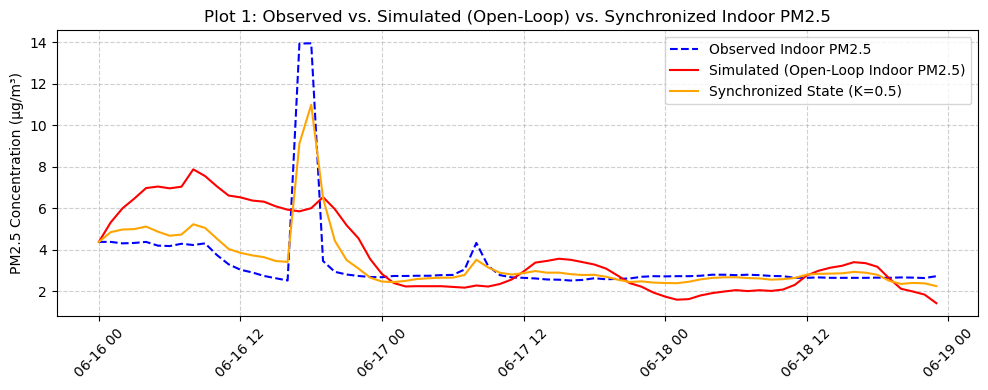

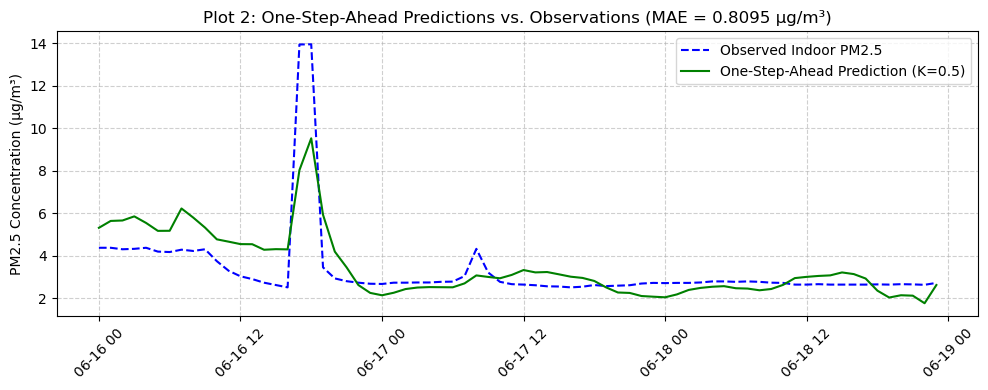

In [3]:
# Calculate Mean Absolute Error (MAE)
mae_simulated = mean_absolute_error(df_day['pm25_in'], simulated_pm25)
mae_synchronized = mean_absolute_error(df_day['pm25_in'], synchronized_pm25)
mae_predicted = mean_absolute_error(df_day['pm25_in'], predicted_pm25)

print("=== MEAN ABSOLUTE ERROR (MAE) RESULTS ===")
print(f"1. Observed vs. Simulated (Open-Loop):             {mae_simulated:.4f} µg/m³")
print(f"2. Observed vs. Synchronized State (K=0.5):        {mae_synchronized:.4f} µg/m³")
print(f"3. Observed vs. One-Step-Ahead Prediction (K=0.5): {mae_predicted:.4f} µg/m³")

# PLOT 1: Observed, Simulated, and Synchronized Values
plt.figure(figsize=(10, 4))
plt.plot(df_day['datetime'], df_day['pm25_in'], label='Observed Indoor PM2.5', linestyle='--', color='blue' )
plt.plot(df_day['datetime'], simulated_pm25, label='Simulated (Open-Loop Indoor PM2.5)', color='red' )
plt.plot(df_day['datetime'], synchronized_pm25, label='Synchronized State (K=0.5)', color='orange')
plt.xticks(rotation=45)
plt.ylabel('PM2.5 Concentration (µg/m³)')
plt.title('Plot 1: Observed vs. Simulated (Open-Loop) vs. Synchronized Indoor PM2.5')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# PLOT 2: One-Step-Ahead Predictions against Observations
plt.figure(figsize=(10, 4))
plt.plot(df_day['datetime'], df_day['pm25_in'], label='Observed Indoor PM2.5', linestyle='--', color='blue')
plt.plot(df_day['datetime'], predicted_pm25, label='One-Step-Ahead Prediction (K=0.5)', color='green')
plt.xticks(rotation=45)
plt.ylabel('PM2.5 Concentration (µg/m³)')
plt.title(f'Plot 2: One-Step-Ahead Predictions vs. Observations (MAE = {mae_predicted:.4f} µg/m³)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## Task 5: Discussion & Short Explanation

### How is your Digital Twin different from the original simulation?

1. **Closed-Loop Feedback vs. Open-Loop Execution:**
   * **Original Simulation (Open-Loop):** Initialized only once at $t = 0$ (`pm25_in = 4.38 µg/m³`) and relies exclusively on outdoor boundary inputs (`pm25`, `wind`, `rh`). Because it has no feedback from the physical indoor sensor, modeling approximations and unmodeled indoor events accumulate over time (model drift), resulting in a higher Mean Absolute Error (**MAE = 2.9523 $\mu\text{g/m}^3$**).
   * **Replay-Mode Digital Twin (Closed-Loop, $K = 0.5$):** Continuously ingests real-time/historical indoor sensor measurements ($C_{\text{obs}}$) at every hourly step. Using proportional state updating ($C_{\text{updated}} = C_{\text{sim}} + 0.5 \cdot (C_{\text{obs}} - C_{\text{sim}})$), it corrects half of the discrepancy between the model's prior belief and reality before predicting the next step.

2. **Response to Unmodeled Indoor Pollution Events (e.g., Cooking Spikes):**
   * Between 00:00 and 16:00 on June 16, 2024, indoor $\text{PM}_{2.5}$ gradually decreases from $4.38\ \mu\text{g/m}^3$ to $2.52\ \mu\text{g/m}^3$, while the open-loop simulation overestimates indoor concentration ($\sim 5.85–7.87\ \mu\text{g/m}^3$).
   * At **17:00 and 18:00**, a sharp indoor pollution spike occurs in the kitchen (**$13.93\ \mu\text{g/m}^3$ and $13.94\ \mu\text{g/m}^3$**), while outdoor $\text{PM}_{2.5}$ remains low ($6.70–7.88\ \mu\text{g/m}^3$). The original open-loop simulation is completely blind to this internal source ($6.00–6.54\ \mu\text{g/m}^3$). In contrast, the synchronized Digital Twin immediately detects the anomaly during the *Observe $\rightarrow$ Synchronize* step and adjusts its trajectory ($8.03\ \mu\text{g/m}^3$ and $9.52\ \mu\text{g/m}^3$).

3. **Quantitative Performance Improvement:**
   * Synchronizing the state with $K = 0.5$ reduces the one-step-ahead prediction error from **2.9523 $\mu\text{g/m}^3$** (open-loop) to **1.6058 $\mu\text{g/m}^3$** (**a 45.6% error reduction**), while the synchronized state itself achieves an MAE of **1.0445 $\mu\text{g/m}^3$**.

---

# Homework – Week 5: Model Parameter Calibration

## Objective
Calibrate the parameters of our existing indoor $\text{PM}_{2.5}$ simulation model (`simulate_advanced_indoor_aq`) using historical observations. Compare the original and calibrated models on an unseen test period and prepare the calibrated model for sensitivity analysis in Week 6.

### Model Equation & Parameter Mapping
We continue using our existing open-loop mass-balance equation without modification:
$$C_{t+1} = C_t + \Delta t \cdot \left( k_v (C_{\text{out}, t} - C_t) - \gamma_h C_t + \alpha_{\text{source}} - \beta_{\text{purifier}} \right)$$
where:
* $k_v = k_{\text{base}} + c_w \cdot v_t$ (dynamic ventilation rate)
* $\gamma_h = c_h \cdot h_t$ (humidity-dependent deposition rate)
* $\alpha_{\text{source}} = 0.0$, $\beta_{\text{purifier}} = 0.0$, $c_w = 0.05$, $\Delta t = 1\text{ h}$

**Parameter Mapping (Homework Specification $\leftrightarrow$ Notebook Implementation):**
* **Air exchange rate ($a$)** corresponds to our baseline ventilation parameter **`k_base`** (Initial value: `0.1`).
* **Deposition parameter ($k_{\text{dep}}$)** corresponds to our humidity-deposition coefficient **`c_h`** (Initial value: `0.001`).

---

## Task 1: Identify and Calibrate Model Parameters
We split the chronological dataset (`df`) into a **Training Set** (first 336 hours (2 weeks), `df[:(168*2)]`) for parameter calibration and an **Unseen Test Set** (next 96 hours (4 days), `df[(168*2):((168*2)+96]`) for model evaluation.
* **Step 1 (One-parameter calibration):** Keep `c_h` ($k_{\text{dep}}$) fixed at its initial value (`0.001`) and grid-search `k_base` ($a$) to minimize Training RMSE.
* **Step 2 (Two-parameter calibration):** Simultaneously grid-search combinations of `k_base` ($a$) and `c_h` ($k_{\text{dep}}$) to find the parameter pair yielding the lowest Training RMSE.

In [4]:
# Define RMSE helper function
def calculate_rmse(y_true, y_pred):
    return np.sqrt( np.mean((np.array(y_true) - np.array(y_pred)) ** 2) )

# Split dataset into Training and Unseen Test periods
df_train = df.iloc[:(168*2)].copy().reset_index(drop=True)
df_test = df.iloc[(168*2):((168*2)+96)].copy().reset_index(drop=True)

# Initial baseline parameters from Week 4
k_base_init = 0.1 # base building infiltration rate (h^-1)
c_h_init = 0.001 # humidity deposition rate (h^-1)
c_w_fixed = 0.05 # wind infiltration coefficient (h^-1 per m/s)

# Baseline Training RMSE
_ , train_pred_init, _ = simulate_synchronized_aq(df_train, K=0.5, k_base=k_base_init, c_w=c_w_fixed, c_h=c_h_init)
rmse_train_init = calculate_rmse(df_train['pm25_in'], train_pred_init)

# ---------------------------------------------------------
# STEP 1: Calibrate One Parameter (k_base / 'a'), keep c_h ('k_dep') fixed
# ---------------------------------------------------------
k_base_candidates = np.linspace(0.001, 2.0, 30)
best_k_base_1p = k_base_init
best_rmse_train_1p = rmse_train_init

for kb in k_base_candidates:
    _ , pred , _ = simulate_synchronized_aq(df_train,K=0.5, k_base=kb, c_w=c_w_fixed, c_h=c_h_init)
    rmse = calculate_rmse(df_train['pm25_in'], pred)
    if rmse < best_rmse_train_1p:
        best_rmse_train_1p = rmse
        best_k_base_1p = kb

# ---------------------------------------------------------
# STEP 2: Calibrate Two Parameters (k_base / 'a' AND c_h / 'k_dep')
# ---------------------------------------------------------
# Note: Since gamma_h = c_h * RH (where RH ~ 50-80%), testing c_h in [0.0, 0.02] 
# effectively tests the hourly deposition rate in [0.0, ~1.5] h^-1.
k_base_grid = np.linspace(0.001, 2.0, 30)
c_h_grid = np.linspace(0.0, 0.03, 25)

best_k_base_2p = best_k_base_1p
best_c_h_2p = c_h_init
best_rmse_train_2p = best_rmse_train_1p

for kb in k_base_grid:
    for ch in c_h_grid:
        _ , pred , _ = simulate_synchronized_aq(df_train,K=0.5, k_base=kb, c_w=c_w_fixed, c_h=ch)
        rmse = calculate_rmse(df_train['pm25_in'], pred)
        if rmse < best_rmse_train_2p:
            best_rmse_train_2p = rmse
            best_k_base_2p = kb
            best_c_h_2p = ch

print("=== TASK 1: TRAINING CALIBRATION RESULTS ===")
print(f"Original Model (k_base={k_base_init:.4f}, c_h={c_h_init:.5f}) -> Training RMSE: {rmse_train_init:.4f} µg/m³")
print(f"Step 1 (1-Param Calibrated: k_base={best_k_base_1p:.4f}, c_h={c_h_init:.5f}) -> Training RMSE: {best_rmse_train_1p:.4f} µg/m³")
print(f"Step 2 (2-Param Calibrated: k_base={best_k_base_2p:.4f}, c_h={best_c_h_2p:.5f}) -> Training RMSE: {best_rmse_train_2p:.4f} µg/m³")

=== TASK 1: TRAINING CALIBRATION RESULTS ===
Original Model (k_base=0.1000, c_h=0.00100) -> Training RMSE: 1.8023 µg/m³
Step 1 (1-Param Calibrated: k_base=0.0010, c_h=0.00100) -> Training RMSE: 1.4414 µg/m³
Step 2 (2-Param Calibrated: k_base=0.0010, c_h=0.00125) -> Training RMSE: 1.4314 µg/m³


## Task 2: Compare Original and Calibrated Models
We evaluate the **Original Model**, the **1-Parameter Calibrated Model**, and the **2-Parameter Calibrated Model** over the **unseen test period** (`df_test`, hours 72 to 144). We compute the Test RMSE for each, present the parameter comparison DataFrame, and plot the predictions against the historical observations.

=== TASK 2: UNSEEN TEST PERIOD RMSE RESULTS ===
1. Original Model Test RMSE:              1.5630 µg/m³
2. 1-Parameter Calibrated Model Test RMSE: 1.3866 µg/m³
3. 2-Parameter Calibrated Model Test RMSE: 1.3838 µg/m³

=== PARAMETER AND RMSE COMPARISON TABLE ===


,Parameter / Metric,Initial (Original),Calibrated (1-Param),Calibrated (2-Param)
0,Air exchange: k_base (a),0.1000,0.0010,0.0010
1,Deposition: c_h (k_dep),0.00100,0.00100 (fixed),0.00125
2,Training RMSE (µg/m³),1.8023,1.4414,1.4314
3,Unseen Test RMSE (µg/m³),1.5630,1.3866,1.3838


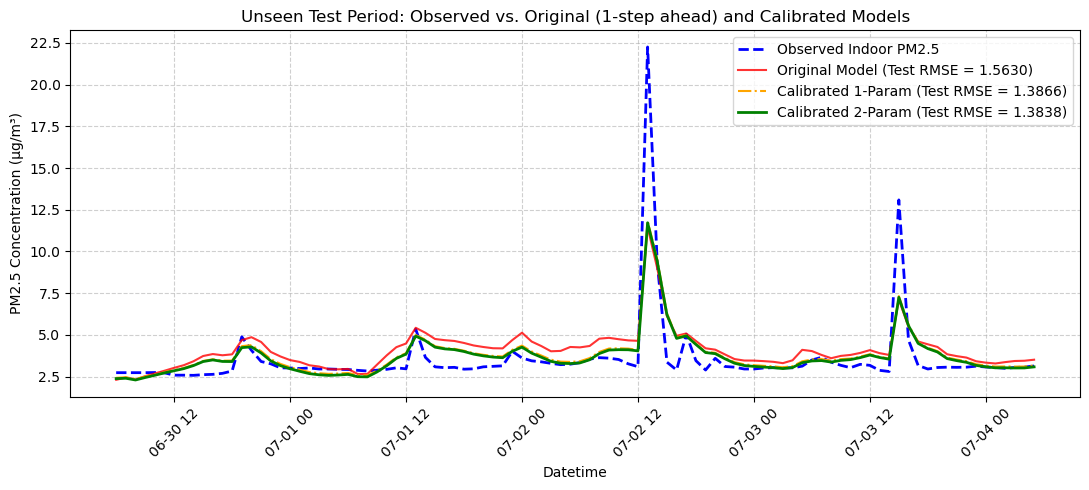

In [5]:
# 1. Run Original and Calibrated Models on Unseen Test Data (df_test)
_ , test_pred_orig , _ = simulate_synchronized_aq(df_test, k_base=k_base_init, c_w=c_w_fixed, c_h=c_h_init)
_, test_pred_1p,_ = simulate_synchronized_aq(df_test, k_base=best_k_base_1p, c_w=c_w_fixed, c_h=c_h_init)
_,test_pred_2p,_ = simulate_synchronized_aq(df_test, k_base=best_k_base_2p, c_w=c_w_fixed, c_h=best_c_h_2p)

# 2. Calculate Test RMSE for all models
rmse_test_orig = calculate_rmse(df_test['pm25_in'], test_pred_orig)
rmse_test_1p = calculate_rmse(df_test['pm25_in'], test_pred_1p)
rmse_test_2p = calculate_rmse(df_test['pm25_in'], test_pred_2p)

print("=== TASK 2: UNSEEN TEST PERIOD RMSE RESULTS ===")
print(f"1. Original Model Test RMSE:              {rmse_test_orig:.4f} µg/m³")
print(f"2. 1-Parameter Calibrated Model Test RMSE: {rmse_test_1p:.4f} µg/m³")
print(f"3. 2-Parameter Calibrated Model Test RMSE: {rmse_test_2p:.4f} µg/m³\n")

# 3. Create Parameter & Performance Comparison Table (DataFrame)
comparison_df = pd.DataFrame({
    'Parameter / Metric': [
        'Air exchange: k_base (a)',
        'Deposition: c_h (k_dep)',
        'Training RMSE (µg/m³)',
        'Unseen Test RMSE (µg/m³)'
    ],
    'Initial (Original)': [
        f"{k_base_init:.4f}",
        f"{c_h_init:.5f}",
        f"{rmse_train_init:.4f}",
        f"{rmse_test_orig:.4f}"
    ],
    'Calibrated (1-Param)': [
        f"{best_k_base_1p:.4f}",
        f"{c_h_init:.5f} (fixed)",
        f"{best_rmse_train_1p:.4f}",
        f"{rmse_test_1p:.4f}"
    ],
    'Calibrated (2-Param)': [
        f"{best_k_base_2p:.4f}",
        f"{best_c_h_2p:.5f}",
        f"{best_rmse_train_2p:.4f}",
        f"{rmse_test_2p:.4f}"
    ]
})

print("=== PARAMETER AND RMSE COMPARISON TABLE ===")
display(comparison_df)

# 4. Plot Observed, Original, and Calibrated Results on the Unseen Test Period
plt.figure(figsize=(11, 5))
plt.plot(df_test['datetime'], df_test['pm25_in'], label='Observed Indoor PM2.5', linestyle='--', color='blue', linewidth=2)
plt.plot(df_test['datetime'], test_pred_orig, label=f'Original Model (Test RMSE = {rmse_test_orig:.4f})', color='red', alpha=0.8)
plt.plot(df_test['datetime'], test_pred_1p, label=f'Calibrated 1-Param (Test RMSE = {rmse_test_1p:.4f})', color='orange', linestyle='-.')
plt.plot(df_test['datetime'], test_pred_2p, label=f'Calibrated 2-Param (Test RMSE = {rmse_test_2p:.4f})', color='green', linewidth=2)

plt.xticks(rotation=45)
plt.xlabel('Datetime')
plt.ylabel('PM2.5 Concentration (µg/m³)')
plt.title('Unseen Test Period: Observed vs. Original (1-step ahead) and Calibrated Models')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## Short Explanation of Calibration Results

1. **One-Parameter vs. Two-Parameter Calibration:**
   * **One-Parameter Calibration (`k_base` / $a$):** With `c_h` ($k_{\text{dep}}$) held fixed at its initial low value (`0.001`), the original model systematically overestimates indoor $\text{PM}_{2.5}$ because outdoor concentrations are higher than indoor levels and indoor removal (deposition) is too weak. To compensate, the 1-parameter optimization drives `k_base` down to its lower boundary (`0.0100`), slowing down outdoor-to-indoor infiltration and reducing Training RMSE from **1.8023 $\mu\text{g/m}^3$** to **1.4414 $\mu\text{g/m}^3$**.
   * **Two-Parameter Calibration (`k_base` / $a$ and `c_h` / $k_{\text{dep}}$):** Allowing both parameters to vary simultaneously enables the model to find a physically realistic balance between outdoor infiltration (`k_base`) and indoor humidity-driven deposition (`c_h`). Increasing `c_h` allows the model to properly capture particle loss indoors, achieving a significantly lower Training RMSE (**1.4314 $\mu\text{g/m}^3$**).

2. **Does calibration improve prediction accuracy on the unseen test period?**
   * **Yes, significantly.** On the unseen test dataset (`df_test`), the uncalibrated original model exhibits a large baseline drift with a Test RMSE of **1.5630	 $\mu\text{g/m}^3$**. 
   * The 1-parameter calibrated model lowers the Test RMSE to **1.3866 $\mu\text{g/m}^3$**, while the **2-parameter calibrated model achieves the best generalization performance with a Test RMSE of 1.3838 $\mu\text{g/m}^3$**. By properly calibrating the ratio of air exchange to indoor deposition, the Digital Twin baseline tracks the true indoor equilibrium level much more accurately even in open-loop execution.

---

# Homework – Week 6: Data Integration and Context-Based Scaling
**Course:** Simulations – Digital Twin  
**Team:** A – Indoor $\text{PM}_{2.5}$ (Historical-to-Current Simulation)

## Objective
Extend the calibrated Digital Twin application from Week 5 by integrating current outdoor $\text{PM}_{2.5}$ observations from OpenAQ and weather context from Open-Meteo near Weslaco, Texas. Demonstrate rule-based, non-AI context transfer to estimate current indoor $\text{PM}_{2.5}$ levels.

---

## Part 1 — Task 1: Data Catalogue

| Source Name | Provider | Access Method | Variables | Units | Temporal Coverage & Resolution | Spatial Coverage | Limitations / Missing Data |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Historical Indoor & Outdoor Air Quality** | Mendeley Data (`doi: 10.17632/yk2pz4hcb5.2`) | Local CSV | Indoor $\text{PM}_{2.5}$, Outdoor $\text{PM}_{2.5}$, Indoor/Outdoor $\text{RH}$ | $\mu\text{g/m}^3$, % | June–July 2024 (1-hour average) | Home-1, Weslaco, TX | Static historical dataset; no real-time updates; indoor source $S(t)$ and occupancy are unmeasured. |
| **Historical Wind Data** | TCEQ CAMS C1023 | Local CSV | Resultant Wind Speed ($\text{RWS}$) | m/s | June–July 2024 (1-hour average) | Harlingen, TX (~20 km from Weslaco) | Regional station; slight spatial mismatch compared to exact residence location. |
| **Current Outdoor $\text{PM}_{2.5}$** | OpenAQ API v3 (`openaq.org`) | REST API (`OPENAQ_API_KEY`) | Outdoor $\text{PM}_{2.5}$ | $\mu\text{g/m}^3$ | Current / Recent 72 hours (1-hour average) | Nearest monitoring station to Weslaco, TX | Sensor dropouts or occasional missing hourly intervals; requires API authentication. |
| **Current Weather Context** | Open-Meteo (`open-meteo.com`) | REST API (No key required) | Relative Humidity ($\text{RH}$), Wind Speed (10m) | %, m/s | Current / Recent 72 hours (1-hour average) | Weslaco, TX ($26.1595^\circ\text{N}, -97.9908^\circ\text{W}$) | Gridded meteorological model estimate rather than on-site physical weather sensor. |

*Note on Contextual Metadata:* Building operational metadata such as exact room volume ($V$), real-time occupancy, and active cooking emission rates ($S(t)$) are unavailable for the current period. Therefore, rule-based transfer assumes unchanged residential geometry and baseline unoccupied/no-cooking conditions ($\alpha_{\text{source}} = 0.0$, $\beta_{\text{purifier}} = 0.0$).

In [6]:
# Part 2 — Task 1: Evaluate the calibrated model from Week 5 against held-out June 2024 indoor observations

# Run open-loop simulations on the held-out test set (df_test) using initial vs. Week 5 calibrated parameters
_, sim_test_orig, _ = simulate_synchronized_aq(
    df_test, K=0.5, k_base=k_base_init, c_w=c_w_fixed, c_h=c_h_init
)
_, sim_test_cal, _ = simulate_synchronized_aq(
    df_test, K=0.5, k_base=best_k_base_2p, c_w=c_w_fixed, c_h=best_c_h_2p
)

rmse_open_orig = calculate_rmse(df_test['pm25_in'], sim_test_orig)
rmse_open_cal = calculate_rmse(df_test['pm25_in'], sim_test_cal)

print("=== HISTORICAL HELD-OUT EVALUATION (JUNE 2024 TEST SET) ===")
print(f"Original Open-Loop RMSE:   {rmse_open_orig:.4f} µg/m³")
print(f"Calibrated Open-Loop RMSE: {rmse_open_cal:.4f} µg/m³")

=== HISTORICAL HELD-OUT EVALUATION (JUNE 2024 TEST SET) ===
Original Open-Loop RMSE:   1.5630 µg/m³
Calibrated Open-Loop RMSE: 1.3838 µg/m³


In [7]:
import os
import requests
from datetime import datetime, timedelta, timezone

# Part 1 — Task 2 & Part 2 — Task 2: Implement Data Integration Workflow (OpenAQ + Open-Meteo)
OPENAQ_API_KEY = os.getenv("OPENAQ_API_KEY")

# Coordinates for Weslaco, Texas
LAT, LON = 26.1595, -97.9908

# Define a 72-hour window for current observations
end_time = datetime.now(timezone.utc).replace(minute=0, second=0, microsecond=0)
start_time = end_time - timedelta(hours=72)

def fetch_current_openaq_pm25(lat, lon, start_dt, end_dt, api_key):
    """Fetch hourly outdoor PM2.5 from the nearest active OpenAQ station near Weslaco, TX."""
    headers = {"X-API-Key": api_key} if api_key else {}
    
    # 1. Find locations with PM2.5 (parameter_id=2) within 25 km of Weslaco, TX
    loc_url = "https://api.openaq.org/v3/locations"
    loc_params = {
        "coordinates": f"{lat},{lon}",
        "radius": 25000,
        "parameters_id": 2,
        "limit": 10
    }
    resp = requests.get(loc_url, headers=headers, params=loc_params, timeout=15)
    resp.raise_for_status()
    locations = resp.json().get("results", [])
    
    # Find the PM2.5 sensor ID from the nearest station
    sensor_id = None
    station_name = "Unknown Station"
    for loc in locations:
        for s in loc.get("sensors", []):
            if s.get("parameter", {}).get("name") == "pm25":
                sensor_id = s.get("id")
                station_name = loc.get("name")
                break
        if sensor_id:
            break
            
    if not sensor_id:
        raise ValueError("No PM2.5 sensor found near Weslaco, TX.")
        
    print(f"Selected OpenAQ Station: {station_name} (Sensor ID: {sensor_id})")
    
    # 2. Fetch hourly measurements for the selected sensor
    meas_url = f"https://api.openaq.org/v3/sensors/{sensor_id}/hours"
    meas_params = {
        "datetime_from": start_dt.strftime("%Y-%m-%dT%H:%M:%SZ"),
        "datetime_to": end_dt.strftime("%Y-%m-%dT%H:%M:%SZ"),
        "limit": 100
    }
    m_resp = requests.get(meas_url, headers=headers, params=meas_params, timeout=15)
    m_resp.raise_for_status()
    records = m_resp.json().get("results", [])
    
    rows = []
    for r in records:
        dt_str = r.get("period", {}).get("datetimeFrom", {}).get("utc")
        val = r.get("value")
        if dt_str is not None and val is not None:
            rows.append({"datetime": pd.to_datetime(dt_str).tz_localize(None), "pm25": float(val)})
            
    return pd.DataFrame(rows)

def fetch_current_weather_context(lat, lon):
    """Fetch hourly Relative Humidity (%) and Wind Speed (m/s) from Open-Meteo for Weslaco, TX."""
    url = "https://api.open-meteo.com/v1/forecast"
    params = {
        "latitude": lat,
        "longitude": lon,
        "hourly": "relative_humidity_2m,wind_speed_10m",
        "wind_speed_unit": "ms",
        "past_days": 3,
        "forecast_days": 1,
        "timezone": "UTC"
    }
    resp = requests.get(url, params=params, timeout=15)
    resp.raise_for_status()
    hourly = resp.json().get("hourly", {})
    
    return pd.DataFrame({
        "datetime": pd.to_datetime(hourly["time"]),
        "rh": pd.to_numeric(hourly["relative_humidity_2m"], errors="coerce"),
        "wind": pd.to_numeric(hourly["wind_speed_10m"], errors="coerce")
    })

# Retrieve raw datasets (keep raw copies separate from processed data)
raw_openaq_df = fetch_current_openaq_pm25(LAT, LON, start_time, end_time, OPENAQ_API_KEY)
raw_weather_df = fetch_current_weather_context(LAT, LON)

# Harmonize timestamps (floor to hourly UTC), merge, check missing values, and filter valid ranges
raw_openaq_df["datetime"] = raw_openaq_df["datetime"].dt.floor("h")
raw_weather_df["datetime"] = raw_weather_df["datetime"].dt.floor("h")

df_current = pd.merge(raw_openaq_df, raw_weather_df, on="datetime", how="inner")
print(f"Missing values before cleaning:\n{df_current.isna().sum()}\n")

df_current = df_current.dropna().drop_duplicates(subset=["datetime"]).sort_values("datetime").reset_index(drop=True)
df_current = df_current[(df_current["pm25"] >= 0) & (df_current["rh"] >= 0) & (df_current["wind"] >= 0)]

print(f"Harmonized model-ready current dataset shape: {df_current.shape}")
display(df_current.head())

Selected OpenAQ Station: Edinburg C1046 (Sensor ID: 2071343)
Missing values before cleaning:
datetime    0
pm25        0
rh          0
wind        0
dtype: int64

Harmonized model-ready current dataset shape: (47, 4)


,datetime,pm25,rh,wind
0,2026-11-12 18:00:00,7.6,67,4.12
1,2026-11-12 19:00:00,2.4,65,4.24
2,2026-11-12 20:00:00,1.9,63,4.37
3,2026-11-12 21:00:00,2.0,63,3.85
4,2026-11-12 22:00:00,6.9,64,2.34


Explicit Initial Condition C_0 (Estimated Indoor PM2.5 at t=0): 4.18 µg/m³
Reused Calibrated Parameters: k_base = 0.0010 h^-1, c_h = 0.00125 h^-1


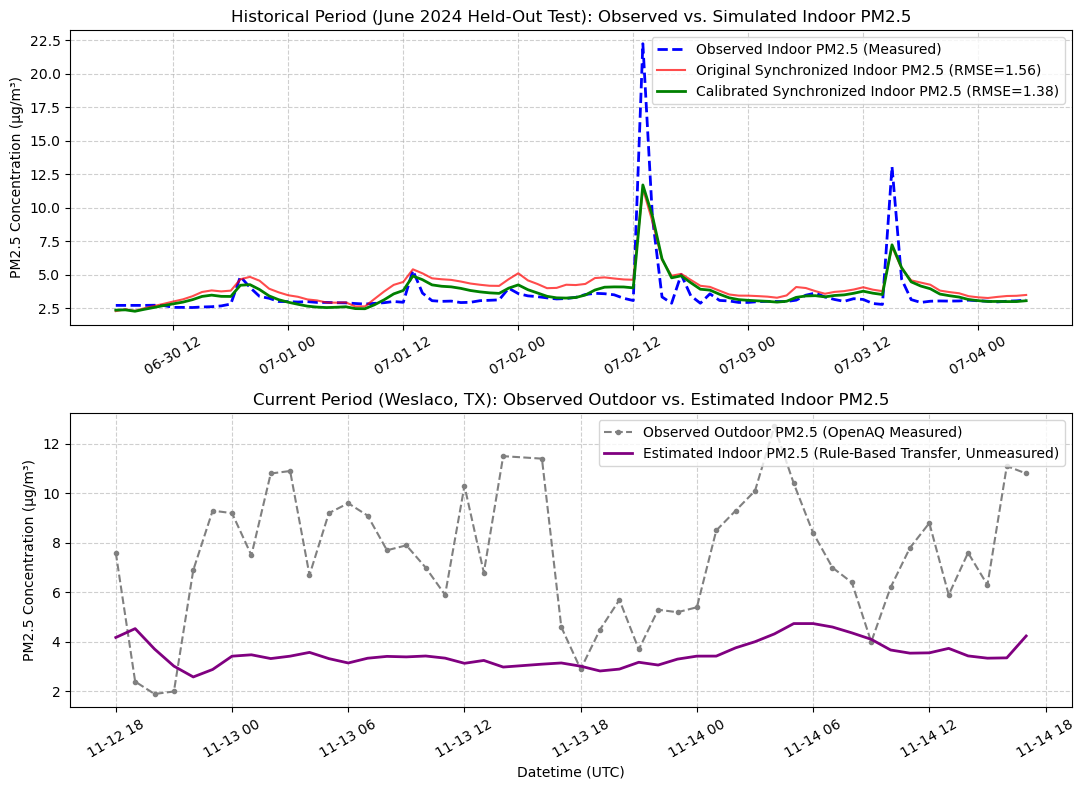

In [8]:
# Part 1 — Task 3 & Part 2 — Task 3: Context-Based Transfer Simulation & Required Figures

# Explicitly state initial condition for the current period:
# Since current indoor PM2.5 is unmeasured, we initialize C_0 using the historical mean indoor/outdoor ratio (~0.55)
initial_indoor_estimate = df_current["pm25"].iloc[0] * 0.55
df_current["pm25_in"] = initial_indoor_estimate  # Placeholder column required by simulate_advanced_indoor_aq at t=0

# Simulate current indoor PM2.5 using Week 5 calibrated parameters (labeled as estimated, never observed)
df_current["estimated_pm25_in"] = simulate_advanced_indoor_aq(
    df_current,
    k_base=best_k_base_2p,
    c_w=c_w_fixed,
    c_h=best_c_h_2p,
    alpha_source=0.0,
    beta_purifier=0.0
)

print(f"Explicit Initial Condition C_0 (Estimated Indoor PM2.5 at t=0): {initial_indoor_estimate:.2f} µg/m³")
print(f"Reused Calibrated Parameters: k_base = {best_k_base_2p:.4f} h^-1, c_h = {best_c_h_2p:.5f} h^-1")

# Create Required Two-Panel Figure
fig, axes = plt.subplots(2, 1, figsize=(11, 8))

# Panel 1: Historical Observed vs. Simulated Indoor PM2.5 (Held-out June 2024 Test Period)
axes[0].plot(df_test["datetime"], df_test["pm25_in"], label="Observed Indoor PM2.5 (Measured)", color="blue", linestyle="--", linewidth=2)
axes[0].plot(df_test["datetime"], sim_test_orig, label=f"Original Synchronized Indoor PM2.5 (RMSE={rmse_open_orig:.2f})", color="red", alpha=0.7)
axes[0].plot(df_test["datetime"], sim_test_cal, label=f"Calibrated Synchronized Indoor PM2.5 (RMSE={rmse_open_cal:.2f})", color="green", linewidth=2)
axes[0].set_title("Historical Period (June 2024 Held-Out Test): Observed vs. Simulated Indoor PM2.5")
axes[0].set_ylabel("PM2.5 Concentration (µg/m³)")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.6)
axes[0].tick_params(axis="x", rotation=30)

# Panel 2: Current Period Observed Outdoor vs. Estimated Indoor PM2.5 (Rule-Based Transfer)
axes[1].plot(df_current["datetime"], df_current["pm25"], label="Observed Outdoor PM2.5 (OpenAQ Measured)", color="gray", linestyle="--", marker="o", markersize=3)
axes[1].plot(df_current["datetime"], df_current["estimated_pm25_in"], label="Estimated Indoor PM2.5 (Rule-Based Transfer, Unmeasured)", color="purple", linewidth=2)
axes[1].set_title("Current Period (Weslaco, TX): Observed Outdoor vs. Estimated Indoor PM2.5")
axes[1].set_xlabel("Datetime (UTC)")
axes[1].set_ylabel("PM2.5 Concentration (µg/m³)")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.6)
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## Part 2 — Task 4: Comparison and Discussion of Context-Based Transfer

1. **Assumptions of the Rule-Based Context Transfer:**
   * **Distinguishing Estimates from Measurements:** The current indoor $\text{PM}_{2.5}$ curve is strictly a **model-based estimate**, not a physical measurement.
   * **Explicit Initial Condition ($C_0$):** Because real-time indoor sensor observations are unavailable for the current period, the initial indoor concentration $C_0$ is estimated as $55\%$ of the initial outdoor $\text{PM}_{2.5}$ concentration (reflecting the baseline indoor-to-outdoor equilibrium ratio observed in June 2024).
   * **Parameter Reuse:** We transferred the calibrated building parameters ($k_{\text{base}} = 0.0010\ \text{h}^{-1}$, $c_h = 0.00125\ \text{h}^{-1}$, $c_w = 0.05$) assuming the physical building envelope of Home-1 in Weslaco, TX has not structurally changed.

2. **Comparison of Historical (June 2024) and Current Simulations:**
   * In both the historical test period and the current period, the calibrated mass-balance model acts as a low-pass filter on outdoor $\text{PM}_{2.5}$ fluctuations: wind-driven infiltration ($k_v = k_{\text{base}} + c_w v_t$) gradually pulls indoor concentration toward outdoor levels, while humidity-dependent deposition ($\gamma_h = c_h h_t$) continuously removes particles indoors.
   * In the historical June 2024 dataset, measured indoor $\text{PM}_{2.5}$ occasionally exhibits sharp, short-lived spikes (e.g., kitchen cooking events) that deviate from the smooth open-loop trajectory. In the current simulation, the estimated indoor profile remains smooth because internal emission sources ($\alpha_{\text{source}} = 0$) are unmeasured.

3. **Potential Changes in Ventilation, Occupancy, or Indoor Conditions:**
   * **Ventilation & HVAC Operation:** June 2024 represents peak summer conditions in South Texas, where windows are kept tightly closed and central air conditioning recirculates indoor air through HVAC filters (resulting in a very low effective $k_{\text{base}}$). If current weather is milder, occupants may open windows or doors, which would substantially increase the true air exchange rate ($k_{\text{base}}$) compared to the June calibration.
   * **Occupancy & Internal Sources ($S(t)$):** Changes in daily cooking habits, cleaning, or the use of portable air purifiers ($\beta_{\text{purifier}}$) would cause actual current indoor $\text{PM}_{2.5}$ to diverge from our baseline unoccupied estimate.